In [318]:
import sys
!{sys.executable} -m pip install --user -qq scikit-learn

In [319]:
!pip install -qq pandas numpy matplotlib seaborn 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

In [320]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
score_lead = pd.read_csv(url)
score_lead.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [321]:
score_lead.info()
score_lead.columns = score_lead.columns.str.lower().str.replace(' ', '_')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [322]:
score_lead.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [323]:
score_lead.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [324]:
categorical_cols = score_lead.select_dtypes(include=['object', 'string']).columns
score_lead[categorical_cols] = score_lead[categorical_cols].fillna('NA')
numerical_cols = score_lead.select_dtypes(include=['float64', 'int64']).columns
score_lead[numerical_cols] = score_lead[numerical_cols].fillna(0.0)
score_lead.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [325]:
df2 = score_lead

In [326]:
df_full_train, df_test = train_test_split(df2, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

In [327]:
numerical_variables = ["lead_score","number_of_courses_viewed","interaction_count","annual_income"]
auc_results = {}
for var in numerical_variables:
  score = roc_auc_score(y_train, df_train[var])
  if score < 0.5:
    score = roc_auc_score(y_train, -df_train[var])
  auc_results[var] = score
sorted_auc = sorted(auc_results.items(), key=lambda x: x[1], reverse=True)
print("AUC scores from highest to lowest:")
for var, score in sorted_auc:
  print(f"- {var}: {score:.3f}")

AUC scores from highest to lowest:
- lead_score: 0.788
- interaction_count: 0.765
- number_of_courses_viewed: 0.723
- annual_income: 0.608


In [328]:
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(f'Model AUC: {auc:.3f}')

Model AUC: 0.732


In [329]:
features = list(df_train.columns)
if 'converted' in features:
  features.remove('converted')

In [330]:
thresholds = np.linspace(0, 1, 101)
precisions = []
recalls = []
for t in thresholds:
    ypred = (y_pred >= t).astype(int)
    tp = (ypred & y_val).sum()
    fp = (ypred & ~y_val).sum()
    fn = (~ypred & y_val).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precisions.append(precision)
    recalls.append(recall)

In [331]:
scores_1 = []
for t in thresholds: 
    tp = ((y_pred >= t) & (y_val == 1)).sum() 
    fp = ((y_pred >= t) & (y_val == 0)).sum() 
    fn = ((y_pred < t) & (y_val == 1)).sum() 
    tn = ((y_pred < t) & (y_val == 0)).sum()
    scores_1.append((t, tp, fp, fn, tn))  
df_scores = pd.DataFrame(scores_1) 
df_scores.columns = ['threshold', 'tp', 'fp', 'fn', 'tn'] 
print('Confusion table for different threshholds')
df_scores[::10]

Confusion table for different threshholds


,threshold,tp,fp,fn,tn
0,0.0,586,414,0,0
10,0.1,586,414,0,0
20,0.2,586,414,0,0
30,0.3,586,403,0,11
40,0.4,573,362,13,52
50,0.5,531,294,55,120
60,0.6,457,190,129,224
70,0.7,311,82,275,332
80,0.8,139,23,447,391
90,0.9,19,1,567,413


In [332]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn) 
df_scores[::10] 

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,586,414,0,0,1.000000,1.000000
10,0.1,586,414,0,0,1.000000,1.000000
20,0.2,586,414,0,0,1.000000,1.000000
30,0.3,586,403,0,11,1.000000,0.973430
40,0.4,573,362,13,52,0.977816,0.874396
50,0.5,531,294,55,120,0.906143,0.710145
60,0.6,457,190,129,224,0.779863,0.458937
70,0.7,311,82,275,332,0.530717,0.198068
80,0.8,139,23,447,391,0.237201,0.055556
90,0.9,19,1,567,413,0.032423,0.002415


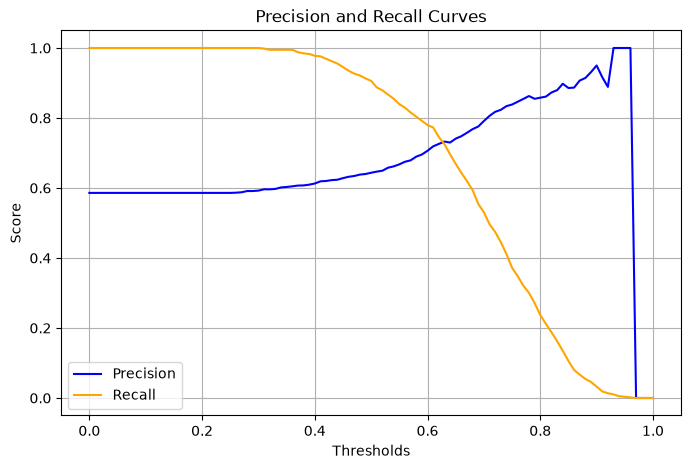

In [333]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label="Precision", color="blue")
plt.plot(thresholds, recalls, label="Recall", color="orange")
plt.xlabel("Thresholds")
plt.ylabel("Score")
plt.title("Precision and Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

In [334]:
valid_indices = [i for i, (p, r) in enumerate(zip(precisions, recalls)) if p > 0 or r > 0]
valid_thresholds = thresholds[valid_indices]
valid_precisions = np.array(precisions)[valid_indices]
valid_recalls = np.array(recalls)[valid_indices]
abs_diffs = np.abs(valid_precisions - valid_recalls)
best_index = np.argmin(abs_diffs)
intersect_threshold = valid_thresholds[best_index]
print(f"The precision and recall curves intersect at threshold: {intersect_threshold:.2f}")

The precision and recall curves intersect at threshold: 0.63


In [336]:
candidate_thresholds = [0.21, 0.41, 0.61, 0.81]
best_f1 = -1
best_threshold = None
for t in candidate_thresholds:
  ypred = (y_pred >= t).astype(int)
  tp = (ypred & y_val).sum()
  fp = (ypred & ~y_val).sum()
  fn = (~ypred & y_val).sum()
  precision = tp / (tp + fp) if (tp + fp) > 0 else 0
  recall = tp / (tp + fn) if (tp + fn) > 0 else 0
  f1 = ((2 * precision * recall) / (precision + recall)
        if (precision + recall) > 0 
        else 0.0)
  print(f"Threshold: {t:.2f} | F1 Score: {f1:.3f}")
  if f1 > best_f1:
    best_f1 = f1
    best_threshold = t
print(f"Maximal F1 score: {best_f1:.3f} achieved at threshold: {best_threshold:.2f}")

Threshold: 0.21 | F1 Score: 0.739
Threshold: 0.41 | F1 Score: 0.758
Threshold: 0.61 | F1 Score: 0.745
Threshold: 0.81 | F1 Score: 0.340
Maximal F1 score: 0.758 achieved at threshold: 0.41


In [337]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
  df_train_fold = df_full_train.iloc[train_idx]
  df_val_fold = df_full_train.iloc[val_idx]
  y_train_fold = df_train_fold['converted'].values
  y_val_fold = df_val_fold['converted'].values
  features = list(df_full_train.columns)
  if 'converted' in features:
    features.remove('converted')
  train_dicts = df_train_fold[features].to_dict(orient='records')
  val_dicts = df_val_fold[features].to_dict(orient='records')
  dv = DictVectorizer(sparse=False)
  X_train_fold = dv.fit_transform(train_dicts)
  X_val_fold = dv.transform(val_dicts)
  model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
  model.fit(X_train_fold, y_train_fold)
  y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
  auc = roc_auc_score(y_val_fold, y_pred_fold)
  scores.append(auc)
std_dev = np.std(scores)
print(f'AUC scores across folds: {[round(s, 3) for s in scores]}')
print(f'Standard Deviation: {std_dev:.3f}')

AUC scores across folds: [0.731, 0.73, 0.736, 0.741, 0.721]
Standard Deviation: 0.007


In [314]:
c_values = [0.000001, 0.001, 1]
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
for C in c_values:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values
        train_dicts = df_train_fold[features].to_dict(orient='records')
        val_dicts = df_val_fold[features].to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(train_dicts)
        X_val_fold = dv.transform(val_dicts)
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_fold, y_train_fold)
        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)
# print('C=%s, auc = %0.3f ± %0.3f' % (C, np.mean(auc), np.std(auc))) 
mean_score = np.mean(scores)
std_score = np.std(scores)
print(f'C with best mean ROC AUC:{C:<8}')
print(f'Mean AUC:{mean_score:.3f} | Std:{std_score:.3f}')

C with best mean ROC AUC:1       
Mean AUC:0.732 | Std:0.007
